# 00 — HT-9046MX Notebook Navigator

### เริ่มอ่านจากไฟล์นี้: แผนที่งานตั้งแต่ Data Contract ถึง Auto-bootstrap

Notebook นี้ไม่ได้สร้างโมเดลเพิ่ม หน้าที่ของมันคือช่วยให้คนเปิดโปรเจกต์ครั้งแรกตอบได้ทันทีว่า **ควรเปิด Notebook ไหน, Notebook นั้นพิสูจน์อะไร, ใช้ข้อมูลจากไหน และข้อจำกัดอยู่ตรงไหน**

## tl;dr

- โปรเจกต์มี **12 Phase หลัก (0–11)** และมี **Phase 5R** เป็น checkpoint ด้าน Deep Research
- Phase 0–5 มีผลวิเคราะห์ที่รันแล้ว แต่บางส่วนยังเป็น exploratory และไม่ได้มี nested HPO/service epoch ในตัว
- Phase 6 มี Notebook Auto-bootstrap แยกต่างหาก พร้อม lifecycle status, uncertainty, event coverage และ shadow replay
- Notebook 07B ตรวจข้อมูล MX เพิ่มเติม, 07C วัด one-second event coverage, 07D เจาะเหตุการณ์ MX-080 Module 6 และ Notebook 07 รัน deterministic server shadow replay แล้ว; Phase 7 ยังมี production blockers
- ไม่มี Notebook ใดมีสิทธิ์ยืนยัน leak หรือเปลี่ยน `ACTIVE_FROZEN` profile เอง

ถ้าต้องพรีเซนต์ภาพรวม ให้เปิด `HT9046MX_Data_Analysis_to_ML_Phased_Colab.ipynb`  
ถ้าจะตรวจความพร้อมของ calibration profile ให้เปิด `06_HT9046MX_AutoBootstrap_Profile_Lifecycle_Colab.ipynb`

## Context & Methods

### 1. โหลดสถานะโปรเจกต์และตรวจ Notebook inventory

In [1]:
import importlib.util
import json
import os
import subprocess
import sys
from pathlib import Path

required = {"pandas": "pandas>=2", "matplotlib": "matplotlib>=3.8"}
missing = [pkg for module, pkg in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

def find_project_root():
    override = os.environ.get("HT9046MX_PROJECT_ROOT", "").strip()
    candidates = [Path(override)] if override else []
    candidates += [Path.cwd(), Path.cwd().parent, Path("/content/OPERATION_P"), Path("/content/drive/MyDrive/OPERATION_P")]
    for candidate in candidates:
        candidate = candidate.resolve()
        if (candidate / "README_System.md").exists():
            return candidate
    raise FileNotFoundError("ไม่พบ README_System.md — ตั้ง HT9046MX_PROJECT_ROOT ก่อน")

PROJECT_ROOT = find_project_root()
NOTEBOOK_ROOT = PROJECT_ROOT / "notebooks"
OUTPUT_ROOT = NOTEBOOK_ROOT / "outputs" / "ht9046mx_navigator"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

phase_rows = [
    {"phase": "0", "topic": "System/Data Contract", "notebook": "— ใช้ README_System.md", "purpose": "ยืนยัน tag, physics, state และข้อห้าม", "status": "Contract updated"},
    {"phase": "1–2", "topic": "Data Quality + State-aware Baseline", "notebook": "HT9046MX_State_Aware_Baseline_Analysis.ipynb", "purpose": "coverage, state gate, baseline รายเครื่อง/โมดูล/SV", "status": "Executed; caveats"},
    {"phase": "1–2 Visual", "topic": "Baseline Visual Story", "notebook": "HT9046MX_Visual_Analysis_Colab.ipynb", "purpose": "กราฟรายเครื่องและความสัมพันธ์ที่อ่านง่าย", "status": "Executed; presentation"},
    {"phase": "3", "topic": "Calibration + Temporal/LOMO", "notebook": "HT9046MX_ML_Calibration_LOMO.ipynb", "purpose": "relative features และ cross-machine screening", "status": "Executed; exploratory"},
    {"phase": "4", "topic": "One-second Event Response", "notebook": "HT9046MX_1Second_Window_Response_Analysis_Colab.ipynb", "purpose": "lag, gain, response shape และ coverage", "status": "Executed; narrow coverage"},
    {"phase": "5", "topic": "Minute vs Second-derived ML", "notebook": "HT9046MX_ML_Minute_vs_SecondDerived_Comparison_Colab.ipynb", "purpose": "feature/latency/transfer comparison", "status": "Executed; exploratory"},
    {"phase": "1–5 Story", "topic": "Presentation Walkthrough", "notebook": "HT9046MX_Data_Analysis_to_ML_Phased_Colab.ipynb", "purpose": "เล่าเรื่องจากข้อมูลถึง ML เป็นลำดับ", "status": "Executed; presentation"},
    {"phase": "5R", "topic": "Deep Research", "notebook": "— ใช้ THESIS.md", "purpose": "model/HPO/bootstrap/Production methodology", "status": "Research complete"},
    {"phase": "6", "topic": "Auto-bootstrap Lifecycle", "notebook": "06_HT9046MX_AutoBootstrap_Profile_Lifecycle_Colab.ipynb", "purpose": "candidate, uncertainty, event readiness, shadow", "status": "Executed candidate v1"},
    {"phase": "07B companion", "topic": "External MX Dataset Intake", "notebook": "07B_HT9046MX_External_Dataset_Intake_Colab.ipynb", "purpose": "source overlap, novel history, module/SV reference and correlations", "status": "Inspect execution/QA below; training separate"},
    {"phase": "07C checkpoint", "topic": "External one-second coverage", "notebook": "07C_HT9046MX_External_OneSecond_Coverage_Colab.ipynb", "purpose": "clean opening/closing coverage by machine/module/SV", "status": "Executed; all response strata remain insufficient"},
    {"phase": "07D forensic", "topic": "MX-080 Module 6 incident", "notebook": "07D_MX080_Module6_OneSecond_Forensics_Colab.ipynb", "purpose": "exact-second pressure/message alignment and incident story", "status": "Executed; technician review, cause unconfirmed"},
    {"phase": "7", "topic": "Server Shadow Replay", "notebook": "07_HT9046MX_Server_Shadow_Replay_Colab.ipynb", "purpose": "locked-model replay, persistence, failure modes and MX-080 probe", "status": "Executed; production blockers remain"},
]
phase_map = pd.DataFrame(phase_rows)

def inspect_notebook(name):
    if name.startswith("—"):
        return {"exists": True, "code_cells": 0, "unrun_cells": 0, "error_outputs": 0}
    path = NOTEBOOK_ROOT / name
    if not path.exists():
        return {"exists": False, "code_cells": 0, "unrun_cells": 0, "error_outputs": 0}
    payload = json.loads(path.read_text(encoding="utf-8"))
    code_cells = [cell for cell in payload.get("cells", []) if cell.get("cell_type") == "code"]
    error_outputs = sum(
        output.get("output_type") == "error"
        for cell in code_cells for output in cell.get("outputs", [])
    )
    unrun = sum(cell.get("execution_count") is None for cell in code_cells)
    return {"exists": True, "code_cells": len(code_cells), "unrun_cells": unrun, "error_outputs": error_outputs}

inspection = phase_map["notebook"].apply(inspect_notebook).apply(pd.Series)
inventory = pd.concat([phase_map, inspection], axis=1)
inventory.to_csv(OUTPUT_ROOT / "notebook_inventory.csv", index=False)
display(inventory)

if not inventory["exists"].all() or inventory["error_outputs"].sum() > 0:
    raise AssertionError("Notebook inventory contains a missing file or saved error output")
print("Inventory PASS: files are present and no saved error output was found")

,phase,topic,notebook,purpose,status,exists,code_cells,unrun_cells,error_outputs
0,0,System/Data Contract,— ใช้ README_System.md,"ยืนยัน tag, physics, state และข้อห้าม",Contract updated,True,0,0,0
1,1–2,Data Quality + State-aware Baseline,HT9046MX_State_Aware_Baseline_Analysis.ipynb,"coverage, state gate, baseline รายเครื่อง/โมดู...",Executed; caveats,True,13,0,0
2,1–2 Visual,Baseline Visual Story,HT9046MX_Visual_Analysis_Colab.ipynb,กราฟรายเครื่องและความสัมพันธ์ที่อ่านง่าย,Executed; presentation,True,17,0,0
3,3,Calibration + Temporal/LOMO,HT9046MX_ML_Calibration_LOMO.ipynb,relative features และ cross-machine screening,Executed; exploratory,True,15,0,0
4,4,One-second Event Response,HT9046MX_1Second_Window_Response_Analysis_Cola...,"lag, gain, response shape และ coverage",Executed; narrow coverage,True,11,0,0
5,5,Minute vs Second-derived ML,HT9046MX_ML_Minute_vs_SecondDerived_Comparison...,feature/latency/transfer comparison,Executed; exploratory,True,11,0,0
6,1–5 Story,Presentation Walkthrough,HT9046MX_Data_Analysis_to_ML_Phased_Colab.ipynb,เล่าเรื่องจากข้อมูลถึง ML เป็นลำดับ,Executed; presentation,True,23,0,0
7,5R,Deep Research,— ใช้ THESIS.md,model/HPO/bootstrap/Production methodology,Research complete,True,0,0,0
8,6,Auto-bootstrap Lifecycle,06_HT9046MX_AutoBootstrap_Profile_Lifecycle_Co...,"candidate, uncertainty, event readiness, shadow",Executed candidate v1,True,18,0,0
9,07B companion,External MX Dataset Intake,07B_HT9046MX_External_Dataset_Intake_Colab.ipynb,"source overlap, novel history, module/SV refer...",Inspect execution/QA below; training separate,True,10,0,0


Inventory PASS: files are present and no saved error output was found


## Data

### 2. สิ่งที่แต่ละ Phase ทำจริงและสิ่งที่ยังขาด

| Phase | ทำแล้ว | ยังไม่ควรเข้าใจว่าเสร็จ |
|---|---|---|
| 0 | Data Contract และกติกา `Hp_2nd` ปรับตามหลักฐานล่าสุด | P&ID/codebook ยังต้องยืนยัน |
| 1–2 | inventory, state gate, baseline และกราฟรายเครื่อง | ยังไม่มี recipe/load/water/service epoch ครบ |
| 3 | relative features, temporal split, LOMO, sparse external test | parameter ยัง fixed; ไม่มี nested HPO/calibration block |
| 4 | one-second closing/SV Off response | opening/SV On ยังข้อมูลไม่พอ |
| 5 | เปรียบเทียบ minute/30s/120s บน late events เดียวกัน | ไม่มี failure labels จึงไม่ใช่ accuracy comparison |
| 5R | เพิ่มแนวทาง bootstrap, HPO, benchmark และ Production QA | เป็น methodology; ไม่ใช่ empirical result ใหม่ |
| 6 | candidate profile, quarantine, stability, bootstrap CI, shadow | service epoch/codebook/approval ยังบล็อก Production |

นี่คือเหตุผลที่ Phase 1–5 ยังถูกเก็บเป็นหลักฐานเดิม แต่ Phase 6 ไม่แอบอ้างว่าฟังก์ชันใหม่เคยอยู่ใน Notebook เก่า

## Results

### 3. แผนภาพการไหลของงาน

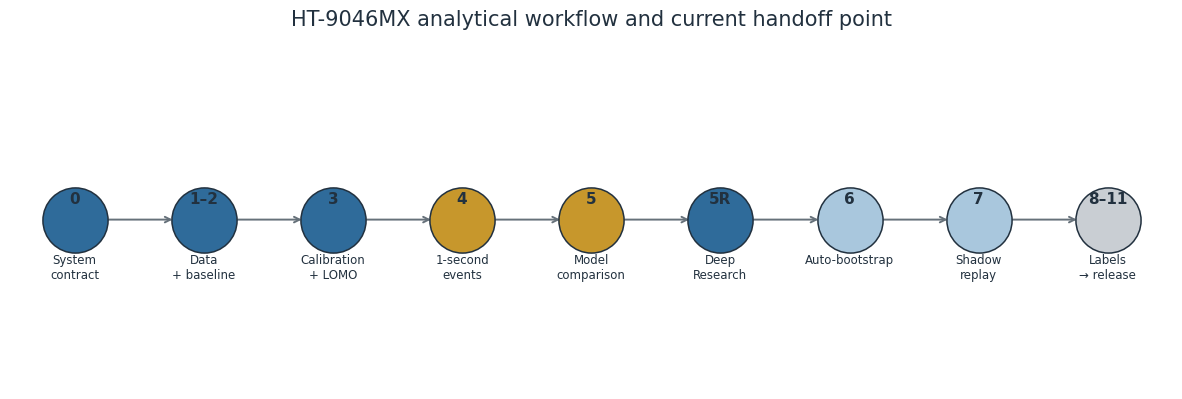

In [2]:
nodes = [
    ("0", "System contract", "done"),
    ("1–2", "Data + baseline", "done"),
    ("3", "Calibration + LOMO", "done"),
    ("4", "1-second events", "limited"),
    ("5", "Model comparison", "limited"),
    ("5R", "Deep Research", "done"),
    ("6", "Auto-bootstrap", "candidate"),
    ("7", "Shadow replay", "candidate"),
    ("8–11", "Labels → release", "blocked"),
]
colors = {"done": "#2F6B9A", "limited": "#C7972C", "candidate": "#A9C7DD", "next": "#C96A3D", "blocked": "#C9CED3"}
fig, ax = plt.subplots(figsize=(15, 4.4))
ax.set_xlim(-.5, len(nodes)-.5)
ax.set_ylim(-.8, .8)
ax.axis("off")
for idx, (phase, label, status) in enumerate(nodes):
    if idx < len(nodes)-1:
        ax.annotate("", xy=(idx+.78, 0), xytext=(idx+.22, 0), arrowprops={"arrowstyle": "->", "color": "#66717A", "lw": 1.4})
    ax.scatter(idx, 0, s=2200, color=colors[status], edgecolor="#22313F", linewidth=1.1, zorder=3)
    ax.text(idx, .10, phase, ha="center", va="center", fontsize=11, fontweight="bold", color="#22313F")
    ax.text(idx, -.16, label.replace(" ", "\n", 1), ha="center", va="top", fontsize=8.5, color="#22313F")
ax.set_title("HT-9046MX analytical workflow and current handoff point", fontsize=15, color="#22313F", pad=18)
fig.savefig(OUTPUT_ROOT / "phase_map.png", dpi=180, bbox_inches="tight", facecolor="white")
plt.show()

### 4. Current verified snapshot

In [3]:
source_summary = PROJECT_ROOT / "notebooks" / "outputs" / "ht9046mx_colab_analysis" / "analysis_summary.json"
bootstrap_summary = PROJECT_ROOT / "notebooks" / "outputs" / "ht9046mx_autobootstrap" / "analysis_summary.json"
base = json.loads(source_summary.read_text(encoding="utf-8"))
auto = json.loads(bootstrap_summary.read_text(encoding="utf-8"))

snapshot = pd.DataFrame([
    {"item": "Raw source", "value": f"{base['raw_rows']:,} rows / {base['machines']} machines"},
    {"item": "Eligible minute-windows", "value": f"{auto['eligible_rows']:,}"},
    {"item": "Steady profiles assessed", "value": f"{auto['steady_profiles']:,}"},
    {"item": "Shadow-validation profiles", "value": f"{auto['steady_status_counts'].get('SHADOW_VALIDATION', 0):,}"},
    {"item": "Profiles requiring review", "value": f"{auto['steady_status_counts'].get('REVIEW_REQUIRED', 0):,}"},
    {"item": "Insufficient steady profiles", "value": f"{auto['steady_status_counts'].get('INSUFFICIENT_DATA', 0):,}"},
    {"item": "Insufficient event strata", "value": f"{auto['event_status_counts'].get('INSUFFICIENT_COVERAGE', 0):,} / {auto['event_strata']:,}"},
    {"item": "Automatic activation", "value": "Not allowed"},
])
display(snapshot)

,item,value
0,Raw source,"26,159,383 rows / 19 machines"
1,Eligible minute-windows,"2,667,008"
2,Steady profiles assessed,262
3,Shadow-validation profiles,39
4,Profiles requiring review,66
5,Insufficient steady profiles,154
6,Insufficient event strata,524 / 524
7,Automatic activation,Not allowed


## Takeaways

### เปิด Notebook ไหนเมื่อมีคำถามแบบใด

- “ข้อมูลครบกี่วัน และ baseline แต่ละเครื่องต่างกันไหม” → Phase 1–2
- “อยากดูกราฟรายเครื่องแบบพรีเซนต์” → Phase 1–5 Story
- “relative feature และ LOMO ทำอย่างไร” → Phase 3
- “หนึ่งวินาทีเห็น lag/response อย่างไร” → Phase 4
- “minute เทียบ 30/120 วินาทีเป็นอย่างไร” → Phase 5
- “เครื่อง/โมดูล/SV นี้พร้อมสร้าง calibration profile หรือยัง” → Phase 6
- “MX-080 Module 6 วันที่ 3–7 เกิดลำดับอะไร” → Notebook 07D
- “ระบบ Shadow จับอะไรได้และพร้อมขึ้น Server หรือยัง” → Notebook 07
- “โมเดลไหนควรทดลองต่อและเพราะอะไร” → `THESIS.md`

### กติกาก่อนแชร์ผล

1. อ่าน `README_System.md` และ `SOT.md` ก่อน
2. แสดง period, timezone caveat, grain, denominator และ state filter
3. แยก anomaly/flag rate ออกจาก fault accuracy
4. ไม่ใช้ `Hp_2nd < 180 psi` หรือ `Hp_2nd > 230 psi` เป็น fault label
5. ไม่ให้ candidate profile หรือ model activate ตัวเอง